### OOP 5: Spezielle Methoden und Dataclasses - Übungen

In Python kann man eigene Klassen so schreiben, dass sie sich wie die eingebauten Typen verhalten: Man kann Objekte mit `==` und `<` vergleichen,
mit `sorted()` sortieren, mit `+` addieren, mit `len()` messen und mit `for` durchlaufen. Dafür gibt es **spezielle Methoden**
mit zwei Unterstrichen vorne und hinten, wie `__init__` und `__str__`, die du schon kennst.

Für Klassen, die vor allem Daten speichern, schreibt Python mit `@dataclass` viele dieser Methoden sogar selbst.

Dieses Notebook ist das fünfte der OOP-Reihe und baut auf dem Notebook über **Typangaben** auf.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Manche Beispiele enden absichtlich mit einer Fehlermeldung. Danach folgen viele kleine Übungen.
Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. __str__ und __repr__

#### Zwei Arten, ein Objekt als Text zu zeigen

- `__str__` liefert den Text für **Menschen**. Ihn benutzen `print(objekt)`, `str(objekt)` und f-Strings.
- `__repr__` liefert eine **genaue** Darstellung für Programmierer, am besten so, wie man das Objekt im Code schreiben würde: `Punkt(3, 4)`.
  Ihn benutzen `repr(objekt)` und die Ausgabe von **Listen, Tupeln und Dictionaries**, die das Objekt enthalten.

Gibt es nur `__repr__`, benutzt `print()` auch diesen. Deshalb schreibt man oft nur `__repr__`.

In [ ]:
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y

    def __repr__(self) -> str:
        return f'Punkt({self.x}, {self.y})'

    def __str__(self) -> str:
        return f'({self.x}|{self.y})'

p = Punkt(3, 4)
print(p)
print(repr(p))
print([p, Punkt(0, 1)])

#### Aufgabe 1.1

Ergänze die Klasse `Punkt` um `__repr__`, sodass `print([Punkt(1, 2), Punkt(3, 4)])` die Ausgabe `[Punkt(1, 2), Punkt(3, 4)]` erzeugt.

**Erwartete Ausgabe:**
```
[Punkt(1, 2), Punkt(3, 4)]
```

In [ ]:
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y


    def __repr__(self) -> str:
        return f'Punkt({self.x}, {self.y})'

print([Punkt(1, 2), Punkt(3, 4)])
```

</details>

#### Aufgabe 1.2

Ergänze die Klasse `Buch` um `__repr__` (Form `Buch('Momo', 1973)`, mit Anführungszeichen um den Titel, nutze `repr(self.titel)`) und `__str__` (Form `Momo (1973)`).
Gib ein Buch mit `print()` aus und dann eine Liste mit zwei Büchern.

**Erwartete Ausgabe:**
```
Momo (1973)
[Buch('Momo', 1973), Buch('Krabat', 1971)]
```

In [ ]:
class Buch:
    def __init__(self, titel: str, jahr: int) -> None:
        self.titel = titel
        self.jahr = jahr
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Buch:
    def __init__(self, titel: str, jahr: int) -> None:
        self.titel = titel
        self.jahr = jahr


    def __repr__(self) -> str:
        return f'Buch({repr(self.titel)}, {self.jahr})'

    def __str__(self) -> str:
        return f'{self.titel} ({self.jahr})'

print(Buch('Momo', 1973))
print([Buch('Momo', 1973), Buch('Krabat', 1971)])
```

</details>

#### Aufgabe 1.3

Ergänze die Klasse `Karte` nur um `__repr__` in der Form `Herz-Ass`. Gib eine Karte mit `print()` und ein Dictionary `{'Ali': Karte('Herz', 'Ass')}` aus.

**Erwartete Ausgabe:**
```
Pik-7
{'Ali': Herz-Ass}
```

In [ ]:
class Karte:
    def __init__(self, farbe: str, wert: str) -> None:
        self.farbe = farbe
        self.wert = wert
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Karte:
    def __init__(self, farbe: str, wert: str) -> None:
        self.farbe = farbe
        self.wert = wert


    def __repr__(self) -> str:
        return f'{self.farbe}-{self.wert}'

print(Karte('Pik', '7'))
print({'Ali': Karte('Herz', 'Ass')})
```

</details>

#### Aufgabe 1.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class A:
    def __repr__(self) -> str:
        return 'R'

    def __str__(self) -> str:
        return 'S'

a = A()
print(a)
print([a, a])
print(f'{a}', repr(a), str(a))

## 2. Vergleichen: __eq__ und __lt__

#### `__eq__` für `==`

Ohne eigene Angabe bedeutet `==` bei eigenen Objekten dasselbe wie `is` (siehe Referenzen im ersten OOP-Notebook).
Mit einer Methode `__eq__(self, other)` legt man selbst fest, wann zwei Objekte gleich sind. `!=` ergibt sich dann von allein.

Ist `other` gar kein Objekt dieser Klasse, gibt man `False` zurück. Auch `in` bei Listen und `liste.count()` benutzen `__eq__`.

In [ ]:
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Punkt):
            return False
        return self.x == other.x and self.y == other.y

p = Punkt(1, 2)
print(p == Punkt(1, 2), p != Punkt(2, 1), p == (1, 2))
print(Punkt(1, 2) in [Punkt(0, 0), Punkt(1, 2)])

#### `__lt__` für `<` und zum Sortieren

`__lt__(self, other)` (*less than*) legt fest, wann ein Objekt **kleiner** ist als ein anderes. Damit funktionieren `<`, `>`
(Python dreht den Vergleich um) und vor allem `sorted()`, `sort()`, `min()` und `max()` **ohne** `key=`.

Für `<=` und `>=` bräuchte man noch `__le__` und `__ge__`.

In [ ]:
class Schueler:
    def __init__(self, name: str, punkte: int) -> None:
        self.name = name
        self.punkte = punkte

    def __lt__(self, other: 'Schueler') -> bool:
        return self.punkte < other.punkte

    def __repr__(self) -> str:
        return f'{self.name}:{self.punkte}'

klasse = [Schueler('Ali', 17), Schueler('Bea', 23), Schueler('Cem', 12)]
print(sorted(klasse))
print(max(klasse))
print(klasse[0] < klasse[1], klasse[0] > klasse[1])

#### Achtung: `__eq__` und Mengen

Schreibt man `__eq__`, kann man die Objekte **nicht mehr** in Mengen stecken oder als Schlüssel in Dictionaries verwenden (`TypeError: unhashable type`).
Dafür bräuchte man zusätzlich die Methode `__hash__`. Bei dataclasses (Abschnitt 5) gibt es dafür eine einfache Lösung.

In [ ]:
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y

    def __eq__(self, other: object) -> bool:
        return isinstance(other, Punkt) and self.x == other.x and self.y == other.y

print({Punkt(1, 2)})

#### Aufgabe 2.1

Ergänze die Klasse `Punkt` um `__eq__`. Gib `Punkt(2, 3) == Punkt(2, 3)`, `Punkt(2, 3) == Punkt(3, 2)` und `Punkt(2, 3) != Punkt(2, 4)` aus.

**Erwartete Ausgabe:**
```
True
False
True
```

In [ ]:
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Punkt:
    def __init__(self, x: int, y: int) -> None:
        self.x = x
        self.y = y


    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Punkt):
            return False
        return self.x == other.x and self.y == other.y

print(Punkt(2, 3) == Punkt(2, 3))
print(Punkt(2, 3) == Punkt(3, 2))
print(Punkt(2, 3) != Punkt(2, 4))
```

</details>

#### Aufgabe 2.2

Ergänze die Klasse `Bruch` um `__eq__`: Zwei Brüche sind gleich, wenn sie denselben Wert haben (über Kreuz multiplizieren). Gib `Bruch(1, 2) == Bruch(3, 6)` aus und
zähle mit `count()`, wie oft `Bruch(1, 2)` in der Liste `brueche` vorkommt.

**Erwartete Ausgabe:**
```
True
3
```

In [ ]:
class Bruch:
    def __init__(self, zaehler: int, nenner: int) -> None:
        self.zaehler = zaehler
        self.nenner = nenner
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Bruch:
    def __init__(self, zaehler: int, nenner: int) -> None:
        self.zaehler = zaehler
        self.nenner = nenner


    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Bruch):
            return False
        return self.zaehler * other.nenner == other.zaehler * self.nenner

brueche = [Bruch(2, 4), Bruch(1, 3), Bruch(5, 10), Bruch(1, 2)]
print(Bruch(1, 2) == Bruch(3, 6))
print(brueche.count(Bruch(1, 2)))
```

</details>

#### Aufgabe 2.3

Ergänze die Klasse `Film` um `__lt__` (nach der Länge in Minuten) und `__repr__` (nur der Titel). Gib die Liste `filme` sortiert aus, dann den längsten und den kürzesten Film.

**Erwartete Ausgabe:**
```
[Toy Story, Shrek, Avatar, Titanic]
Titanic Toy Story
```

In [ ]:
class Film:
    def __init__(self, titel: str, minuten: int) -> None:
        self.titel = titel
        self.minuten = minuten
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Film:
    def __init__(self, titel: str, minuten: int) -> None:
        self.titel = titel
        self.minuten = minuten


    def __lt__(self, other: 'Film') -> bool:
        return self.minuten < other.minuten

    def __repr__(self) -> str:
        return self.titel

filme = [Film('Titanic', 194), Film('Shrek', 90), Film('Avatar', 162), Film('Toy Story', 81)]
print(sorted(filme))
print(max(filme), min(filme))
```

</details>

#### Aufgabe 2.4

Ergänze die Klasse `Uhrzeit` um `__lt__` und `__eq__`, damit man Uhrzeiten vergleichen kann (erst Stunde, dann Minute), und um `__repr__` in der Form `08:05`.
Gib die Termine sortiert aus und ob `Uhrzeit(9, 30) < Uhrzeit(10, 0)` ist.

**Erwartete Ausgabe:**
```
[08:05, 08:30, 09:45, 14:00]
True
```

In [ ]:
class Uhrzeit:
    def __init__(self, stunde: int, minute: int) -> None:
        self.stunde = stunde
        self.minute = minute
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Uhrzeit:
    def __init__(self, stunde: int, minute: int) -> None:
        self.stunde = stunde
        self.minute = minute


    def __lt__(self, other: 'Uhrzeit') -> bool:
        return (self.stunde, self.minute) < (other.stunde, other.minute)

    def __eq__(self, other: object) -> bool:
        return isinstance(other, Uhrzeit) and self.stunde == other.stunde and self.minute == other.minute

    def __repr__(self) -> str:
        return f'{self.stunde:02d}:{self.minute:02d}'

termine = [Uhrzeit(14, 0), Uhrzeit(8, 5), Uhrzeit(9, 45), Uhrzeit(8, 30)]
print(sorted(termine))
print(Uhrzeit(9, 30) < Uhrzeit(10, 0))
```

</details>

In der Aufgabe davor vergleicht `__lt__` zwei **Tupel**: `(9, 30) < (10, 0)`. Tupel werden Element für Element verglichen, erst das erste,
bei Gleichheit das zweite usw. So kann man bequem nach mehreren Merkmalen vergleichen.

In [ ]:
print((9, 30) < (10, 0), (9, 30) < (9, 15), ('Bea', 2) < ('Bea', 3))

#### Aufgabe 2.5

Ergänze die Klasse `Spieler` um `__lt__`: Wer **mehr** Punkte hat, ist „kleiner“ (kommt beim Sortieren nach vorne); bei gleichen Punkten entscheidet der Name alphabetisch.
Gib die Rangliste sortiert aus.

**Erwartete Ausgabe:**
```
[Ali(45), Bea(30), Cem(30), Dana(12)]
```

In [ ]:
class Spieler:
    def __init__(self, name: str, punkte: int) -> None:
        self.name = name
        self.punkte = punkte

    def __repr__(self) -> str:
        return f'{self.name}({self.punkte})'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Spieler:
    def __init__(self, name: str, punkte: int) -> None:
        self.name = name
        self.punkte = punkte

    def __repr__(self) -> str:
        return f'{self.name}({self.punkte})'


    def __lt__(self, other: 'Spieler') -> bool:
        return (-self.punkte, self.name) < (-other.punkte, other.name)

print(sorted([Spieler('Cem', 30), Spieler('Ali', 45), Spieler('Bea', 30), Spieler('Dana', 12)]))
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Zahl:
    def __init__(self, n: int) -> None:
        self.n = n

    def __eq__(self, other: object) -> bool:
        return isinstance(other, Zahl) and self.n % 10 == other.n % 10

print(Zahl(13) == Zahl(23), Zahl(13) == Zahl(14))
print(Zahl(5) in [Zahl(1), Zahl(15)])
print(Zahl(5) is Zahl(5))

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self, n: int) -> None:
        self.n = n

    def __lt__(self, other: 'Box') -> bool:
        return self.n > other.n

    def __repr__(self) -> str:
        return str(self.n)

print(sorted([Box(2), Box(9), Box(4)]))
print(min([Box(2), Box(9), Box(4)]))

## 3. Rechnen: __add__, __sub__, __mul__

#### Eigene Rechenzeichen

Mit `__add__(self, other)` legt man fest, was `a + b` bedeutet. Die Methode gibt ein **neues** Objekt zurück und verändert `a` und `b` nicht.
Ebenso gibt es `__sub__` für `-`, `__mul__` für `*` und `__truediv__` für `/`.

`other` muss nicht dieselbe Klasse sein: Bei `vektor * 3` ist `other` eine Zahl.

In [ ]:
class Vektor:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    def __add__(self, other: 'Vektor') -> 'Vektor':
        return Vektor(self.x + other.x, self.y + other.y)

    def __mul__(self, faktor: float) -> 'Vektor':
        return Vektor(self.x * faktor, self.y * faktor)

    def __repr__(self) -> str:
        return f'Vektor({self.x}, {self.y})'

a = Vektor(1, 2)
b = Vektor(3, -1)
print(a + b)
print(a * 3)
print(a + b * 2)

#### Aufgabe 3.1

Ergänze die Klasse `Vektor` um `__add__` und `__sub__`. Gib `Vektor(5, 3) + Vektor(1, 1)` und `Vektor(5, 3) - Vektor(1, 1)` aus.

**Erwartete Ausgabe:**
```
Vektor(6, 4)
Vektor(4, 2)
```

In [ ]:
class Vektor:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    def __repr__(self) -> str:
        return f'Vektor({self.x}, {self.y})'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Vektor:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    def __repr__(self) -> str:
        return f'Vektor({self.x}, {self.y})'


    def __add__(self, other: 'Vektor') -> 'Vektor':
        return Vektor(self.x + other.x, self.y + other.y)

    def __sub__(self, other: 'Vektor') -> 'Vektor':
        return Vektor(self.x - other.x, self.y - other.y)

print(Vektor(5, 3) + Vektor(1, 1))
print(Vektor(5, 3) - Vektor(1, 1))
```

</details>

#### Aufgabe 3.2

Ergänze die Klasse `Vektor` um `__add__` und eine Methode `laenge()` (Wurzel mit `** 0.5`). Ein Wanderer läuft nacheinander die Wege in `wege`.
Addiere alle Wege zu einem Gesamtvektor (Start: `Vektor(0, 0)`) und gib ihn und seine Länge aus.

**Erwartete Ausgabe:**
```
Vektor(6, 8)
10.0
```

In [ ]:
class Vektor:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    def __repr__(self) -> str:
        return f'Vektor({self.x}, {self.y})'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Vektor:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    def __repr__(self) -> str:
        return f'Vektor({self.x}, {self.y})'


    def __add__(self, other: 'Vektor') -> 'Vektor':
        return Vektor(self.x + other.x, self.y + other.y)

    def laenge(self) -> float:
        return (self.x ** 2 + self.y ** 2) ** 0.5

wege = [Vektor(3, 0), Vektor(0, 2), Vektor(-1, 2), Vektor(4, 4)]
gesamt = Vektor(0, 0)
for w in wege:
    gesamt = gesamt + w
print(gesamt)
print(gesamt.laenge())
```

</details>

#### Aufgabe 3.3

Ergänze die Klasse `Bruch` um `__add__` und `__mul__` (ohne Kürzen) und `__repr__` in der Form `3/4`. Gib `Bruch(1, 2) + Bruch(1, 3)` und `Bruch(2, 3) * Bruch(3, 4)` aus.

**Erwartete Ausgabe:**
```
5/6
6/12
```

In [ ]:
class Bruch:
    def __init__(self, zaehler: int, nenner: int) -> None:
        self.zaehler = zaehler
        self.nenner = nenner
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Bruch:
    def __init__(self, zaehler: int, nenner: int) -> None:
        self.zaehler = zaehler
        self.nenner = nenner


    def __add__(self, other: 'Bruch') -> 'Bruch':
        return Bruch(self.zaehler * other.nenner + other.zaehler * self.nenner, self.nenner * other.nenner)

    def __mul__(self, other: 'Bruch') -> 'Bruch':
        return Bruch(self.zaehler * other.zaehler, self.nenner * other.nenner)

    def __repr__(self) -> str:
        return f'{self.zaehler}/{self.nenner}'

print(Bruch(1, 2) + Bruch(1, 3))
print(Bruch(2, 3) * Bruch(3, 4))
```

</details>

#### Aufgabe 3.4

Ergänze die Klasse `Geld` (Betrag in Cent, damit es keine Rundungsfehler gibt) um `__add__`, `__mul__` (mit einer ganzen Zahl) und `__repr__` in der Form `12.50 €`.
Berechne den Preis für 3 Hefte zu 1.20 € und 2 Mappen zu 2.45 € und gib ihn aus.

**Erwartete Ausgabe:**
```
8.50 €
```

In [ ]:
class Geld:
    def __init__(self, cent: int) -> None:
        self.cent = cent
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Geld:
    def __init__(self, cent: int) -> None:
        self.cent = cent


    def __add__(self, other: 'Geld') -> 'Geld':
        return Geld(self.cent + other.cent)

    def __mul__(self, anzahl: int) -> 'Geld':
        return Geld(self.cent * anzahl)

    def __repr__(self) -> str:
        return f'{self.cent // 100}.{self.cent % 100:02d} €'

heft = Geld(120)
mappe = Geld(245)
print(heft * 3 + mappe * 2)
```

</details>

#### Aufgabe 3.5

Ergänze die Klasse `Zeitspanne` (in Minuten) um `__add__`, `__lt__` und `__repr__` in der Form `1 h 35 min`. Addiere alle Spannen in `spannen`, gib die Summe aus
und die längste Spanne mit `max()`.

**Erwartete Ausgabe:**
```
3 h 35 min
1 h 30 min
```

In [ ]:
class Zeitspanne:
    def __init__(self, minuten: int) -> None:
        self.minuten = minuten
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Zeitspanne:
    def __init__(self, minuten: int) -> None:
        self.minuten = minuten


    def __add__(self, other: 'Zeitspanne') -> 'Zeitspanne':
        return Zeitspanne(self.minuten + other.minuten)

    def __lt__(self, other: 'Zeitspanne') -> bool:
        return self.minuten < other.minuten

    def __repr__(self) -> str:
        return f'{self.minuten // 60} h {self.minuten % 60} min'

spannen = [Zeitspanne(45), Zeitspanne(90), Zeitspanne(20), Zeitspanne(60)]
summe = Zeitspanne(0)
for s in spannen:
    summe = summe + s
print(summe)
print(max(spannen))
```

</details>

#### Aufgabe 3.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Z:
    def __init__(self, n: int) -> None:
        self.n = n

    def __add__(self, other: 'Z') -> 'Z':
        return Z(self.n * 10 + other.n)

    def __repr__(self) -> str:
        return f'Z{self.n}'

a = Z(1)
b = a + Z(2)
c = b + Z(3)
print(a, b, c)

#### Aufgabe 3.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Z:
    def __init__(self, n: int) -> None:
        self.n = n

    def __add__(self, other: 'Z') -> 'Z':
        return Z(self.n + other.n)

print((Z(1) + Z(2)).n)
print(Z(1) - Z(2))

## 4. Sammlungen: __len__, __getitem__, __contains__, __iter__

#### Eine Klasse wie eine Liste benutzen

Speichert eine Klasse viele Elemente (z. B. eine Playlist), kann man sie wie eine Liste benutzbar machen:

| Methode | ermöglicht |
|---|---|
| `__len__(self)` | `len(objekt)` |
| `__getitem__(self, i)` | `objekt[i]` |
| `__contains__(self, x)` | `x in objekt` |
| `__iter__(self)` | `for x in objekt:` |

`__iter__` muss einen **Iterator** zurückgeben. Am einfachsten gibt man mit `iter(...)` einen Iterator über die interne Liste zurück
(siehe Notebook zu `itertools`).

In [ ]:
class Playlist:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__songs: list[str] = []

    def hinzufuegen(self, song: str) -> None:
        self.__songs.append(song)

    def __len__(self) -> int:
        return len(self.__songs)

    def __getitem__(self, i: int) -> str:
        return self.__songs[i]

    def __contains__(self, song: str) -> bool:
        return song in self.__songs

    def __iter__(self):
        return iter(self.__songs)

p = Playlist('Sport')
for s in ['Run', 'Jump', 'Shout']:
    p.hinzufuegen(s)
print(len(p), p[0], p[-1])
print('Jump' in p, 'Sleep' in p)
for song in p:
    print(song)

#### Aufgabe 4.1

Ergänze die Klasse `Klasse` um `__len__` und `__contains__`. Gib `len(k)` aus und ob `Bea` und `Emil` in der Klasse sind.

**Erwartete Ausgabe:**
```
4
True False
```

In [ ]:
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)


    def __len__(self) -> int:
        return len(self.__schueler)

    def __contains__(self, name: str) -> bool:
        return name in self.__schueler

k = Klasse('9a')
for n in ['Ali', 'Bea', 'Cem', 'Dana']:
    k.aufnehmen(n)
print(len(k))
print('Bea' in k, 'Emil' in k)
```

</details>

#### Aufgabe 4.2

Ergänze die Klasse `Klasse` um `__getitem__` und `__iter__`. Gib `k[1]` aus und dann alle Namen mit einer `for`-Schleife in einer Zeile (mit `end=' '`).

**Erwartete Ausgabe:**
```
Bea
Ali Bea Cem Dana
```

In [ ]:
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)


    def __getitem__(self, i: int) -> str:
        return self.__schueler[i]

    def __iter__(self):
        return iter(self.__schueler)

k = Klasse('9a')
for n in ['Ali', 'Bea', 'Cem', 'Dana']:
    k.aufnehmen(n)
print(k[1])
for name in k:
    print(name, end=' ')
print()
```

</details>

#### Aufgabe 4.3

Ergänze die Klasse `Klasse` um `__iter__`. Dann funktionieren auch `sorted(k)`, `list(k)` und `max(k)`, weil diese Funktionen ihr Argument durchlaufen.
Gib `sorted(k, reverse=True)` und `max(k)` aus.

**Erwartete Ausgabe:**
```
['Dana', 'Cem', 'Bea', 'Ali']
Dana
```

In [ ]:
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Klasse:
    def __init__(self, name: str) -> None:
        self.__name = name
        self.__schueler: list[str] = []

    def aufnehmen(self, name: str) -> None:
        self.__schueler.append(name)


    def __iter__(self):
        return iter(self.__schueler)

k = Klasse('9a')
for n in ['Ali', 'Bea', 'Cem', 'Dana']:
    k.aufnehmen(n)
print(sorted(k, reverse=True))
print(max(k))
```

</details>

#### Aufgabe 4.4

Schreibe eine Klasse `Wort` mit dem Attribut `text`, die `__len__` (Anzahl der Buchstaben), `__getitem__` (Buchstabe an Position `i`), `__contains__` (kommt ein Buchstabe vor,
ohne Groß- und Kleinschreibung zu beachten) und `__iter__` hat. Gib für `Wort('Python')` die Länge, den letzten Buchstaben, ob `p` vorkommt und alle Buchstaben mit `-` verbunden aus.

**Erwartete Ausgabe:**
```
6 n True
P-y-t-h-o-n
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Wort:
    def __init__(self, text: str) -> None:
        self.text = text

    def __len__(self) -> int:
        return len(self.text)

    def __getitem__(self, i: int) -> str:
        return self.text[i]

    def __contains__(self, b: str) -> bool:
        return b.lower() in self.text.lower()

    def __iter__(self):
        return iter(self.text)

w = Wort('Python')
print(len(w), w[-1], 'p' in w)
print('-'.join(w))
```

</details>

#### Aufgabe 4.5

Schreibe eine Klasse `Kartenstapel`, die beim Erzeugen eine Liste von Karten bekommt. `ziehen()` entfernt die oberste Karte (das erste Element) und gibt sie zurück.
`__len__` gibt die Anzahl der restlichen Karten zurück. Ziehe Karten, solange der Stapel nicht leer ist (`while len(stapel) > 0`), und gib sie aus.

**Erwartete Ausgabe:**
```
Herz-7 2
Pik-Ass 1
Karo-10 0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Kartenstapel:
    def __init__(self, karten: list[str]) -> None:
        self.__karten = list(karten)

    def ziehen(self) -> str:
        return self.__karten.pop(0)

    def __len__(self) -> int:
        return len(self.__karten)

stapel = Kartenstapel(['Herz-7', 'Pik-Ass', 'Karo-10'])
while len(stapel) > 0:
    print(stapel.ziehen(), len(stapel))
```

</details>

#### `len()` als Wahrheitswert

Hat eine Klasse `__len__`, gilt ein Objekt mit Länge 0 als **falsch**, so wie eine leere Liste. Statt `while len(stapel) > 0:` kann man dann einfach `while stapel:` schreiben.

In [ ]:
class Stapel:
    def __init__(self) -> None:
        self.__teile: list[int] = [1, 2]

    def __len__(self) -> int:
        return len(self.__teile)

    def weg(self) -> int:
        return self.__teile.pop()

s = Stapel()
while s:
    print(s.weg())
print(bool(s))

#### Aufgabe 4.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Reihe:
    def __init__(self, n: int) -> None:
        self.n = n

    def __len__(self) -> int:
        return self.n

    def __getitem__(self, i: int) -> int:
        return i * i

    def __contains__(self, x: int) -> bool:
        return x % 2 == 0

r = Reihe(5)
print(len(r), r[3], 4 in r, 7 in r)
print(bool(Reihe(0)))

## 5. Dataclasses

#### `@dataclass`

Viele Klassen speichern vor allem Daten. Ihr Konstruktor, `__repr__` und `__eq__` sehen immer gleich aus. Mit dem Dekorator `@dataclass` aus dem Modul
`dataclasses` schreibt Python diese Methoden **selbst**. Man gibt nur die Attribute (**Felder**) mit ihren **Typangaben** an:

```python
@dataclass
class Punkt:
    x: int
    y: int
```

Damit bekommt `Punkt` automatisch
- einen Konstruktor `Punkt(x, y)` mit den Feldern in dieser Reihenfolge,
- ein `__repr__` in der Form `Punkt(x=3, y=4)`,
- ein `__eq__`, das alle Felder vergleicht.

Die Typangaben sind hier **Pflicht**: Nur Zeilen mit Typangabe werden zu Feldern.

In [ ]:
from dataclasses import dataclass

@dataclass
class Punkt:
    x: int
    y: int

p = Punkt(3, 4)
q = Punkt(y=4, x=3)
print(p)
print(p == q, p is q)
print(p.x + p.y)
print([Punkt(0, 0), Punkt(1, 1)])

#### Standardwerte und Methoden

- Felder können **Standardwerte** haben: `anzahl: int = 1`. Felder mit Standardwert müssen **nach** den Feldern ohne Standardwert stehen.
- Für Listen und Dictionaries als Standardwert braucht man `field(default_factory=list)`. Sonst würden sich alle Objekte **eine** Liste teilen.
- Eigene **Methoden** schreibt man ganz normal dazu.

In [ ]:
from dataclasses import dataclass, field

@dataclass
class Artikel:
    name: str
    preis: float
    anzahl: int = 1

    def gesamt(self) -> float:
        return self.preis * self.anzahl

@dataclass
class Warenkorb:
    kunde: str
    artikel: list[Artikel] = field(default_factory=list)

    def summe(self) -> float:
        s = 0
        for a in self.artikel:
            s += a.gesamt()
        return s

w = Warenkorb('Ali')
w.artikel.append(Artikel('Heft', 1.5, 4))
w.artikel.append(Artikel('Mappe', 2.5))
print(w.artikel[1])
print(w.summe())

#### Sortieren, unveränderlich, Prüfen

- `@dataclass(order=True)` erzeugt auch `<`, `<=`, `>`, `>=`. Verglichen wird wie bei Tupeln: erst das erste Feld, dann das zweite usw.
- `@dataclass(frozen=True)` macht die Objekte **unveränderlich** (wie Tupel). Zuweisen gibt einen Fehler (`FrozenInstanceError`).
  Dafür kann man sie in Mengen stecken und als Schlüssel in Dictionaries verwenden.
- Eine Methode `__post_init__(self)` wird direkt nach dem automatischen Konstruktor aufgerufen. Dort kann man Werte prüfen.
- `asdict(objekt)` macht aus einem Objekt ein Dictionary.

In [ ]:
from dataclasses import dataclass, asdict

@dataclass(order=True)
class Note:
    wert: int
    fach: str

    def __post_init__(self) -> None:
        if self.wert < 1 or self.wert > 6:
            raise ValueError('Note muss zwischen 1 und 6 liegen')

@dataclass(frozen=True)
class Feld:
    zeile: int
    spalte: int

noten = [Note(3, 'Mathe'), Note(1, 'Kunst'), Note(3, 'Bio')]
print(sorted(noten))
print(asdict(noten[0]))
besucht = {Feld(0, 0), Feld(0, 1), Feld(0, 0)}
print(len(besucht))
try:
    Note(7, 'Sport')
except ValueError as e:
    print(e)
f = Feld(2, 3)
f.zeile = 5

#### Aufgabe 5.1

Schreibe eine Dataclass `Buch` mit den Feldern `titel` (Text), `autor` (Text) und `seiten` (ganze Zahl). Erzeuge „Momo“ von Michael Ende mit 304 Seiten und gib es aus.

*Die Typangaben der Felder sind hier Pflicht, Python prüft aber nicht, ob die Werte dazu passen. Vergleiche deine Typangaben mit der Lösung.*

**Erwartete Ausgabe:**
```
Buch(titel='Momo', autor='Michael Ende', seiten=304)
```

In [ ]:
from dataclasses import dataclass
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Buch:
    titel: str
    autor: str
    seiten: int

print(Buch('Momo', 'Michael Ende', 304))
```

</details>

#### Aufgabe 5.2

Vergleiche zwei Bücher mit gleichen Feldern mit `==` und mit `is`. Gib außerdem aus, ob ein Buch mit anderer Seitenzahl gleich ist.

**Erwartete Ausgabe:**
```
True False
False
```

In [ ]:
from dataclasses import dataclass

@dataclass
class Buch:
    titel: str
    seiten: int
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Buch:
    titel: str
    seiten: int

a = Buch('Krabat', 336)
b = Buch('Krabat', 336)
print(a == b, a is b)
print(a == Buch('Krabat', 340))
```

</details>

#### Aufgabe 5.3

Setze die Klasse aus dem Diagramm als Dataclass um, mit einer Methode `alter_im_jahr(jahr)`. Gib die Person aus und ihr Alter im Jahr 2030.

*Die Typangaben der Felder sind hier Pflicht, Python prüft aber nicht, ob die Werte dazu passen. Vergleiche deine Typangaben mit der Lösung.*

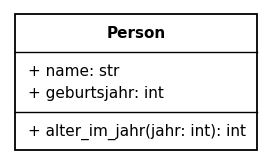



**Erwartete Ausgabe:**
```
Person(name='Ida', geburtsjahr=2011)
19
```

In [ ]:
from dataclasses import dataclass
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Person:
    name: str
    geburtsjahr: int

    def alter_im_jahr(self, jahr: int) -> int:
        return jahr - self.geburtsjahr

p = Person('Ida', 2011)
print(p)
print(p.alter_im_jahr(2030))
```

</details>

#### Aufgabe 5.4

Schreibe eine Dataclass `Termin` mit `titel` (Text), `tag` (ganze Zahl) und `ganztags` (Wahrheitswert, Standardwert `False`). Erzeuge einen Termin mit und einen ohne Angabe von
`ganztags` und gib beide aus.

*Die Typangaben der Felder sind hier Pflicht, Python prüft aber nicht, ob die Werte dazu passen. Vergleiche deine Typangaben mit der Lösung.*

**Erwartete Ausgabe:**
```
Termin(titel='Mathe-Arbeit', tag=12, ganztags=False)
Termin(titel='Wandertag', tag=20, ganztags=True)
```

In [ ]:
from dataclasses import dataclass
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Termin:
    titel: str
    tag: int
    ganztags: bool = False

print(Termin('Mathe-Arbeit', 12))
print(Termin('Wandertag', 20, True))
```

</details>

#### Aufgabe 5.5

Schreibe eine Dataclass `Team` mit `name` (Text) und `mitglieder` (Liste von Texten, Standard: leere Liste mit `field(default_factory=list)`) und einer Methode `aufnehmen(name)`.
Erzeuge zwei Teams, nimm in das erste Mia und Ida auf und gib beide Teams aus. (Beide müssen eigene Listen haben.)

**Erwartete Ausgabe:**
```
Team(name='Rot', mitglieder=['Mia', 'Ida'])
Team(name='Blau', mitglieder=[])
```

In [ ]:
from dataclasses import dataclass, field
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass, field

@dataclass
class Team:
    name: str
    mitglieder: list[str] = field(default_factory=list)

    def aufnehmen(self, name: str) -> None:
        self.mitglieder.append(name)

rot = Team('Rot')
blau = Team('Blau')
rot.aufnehmen('Mia')
rot.aufnehmen('Ida')
print(rot)
print(blau)
```

</details>

#### Aufgabe 5.6

Schreibe eine Dataclass `Spieler` mit `order=True` und den Feldern `punkte` (ganze Zahl) und `name` (Text), in **dieser** Reihenfolge. Sortiere die Spieler aus `daten` und gib sie aus.
Gib danach den Spieler mit den meisten Punkten aus.

**Erwartete Ausgabe:**
```
[Spieler(punkte=12, name='Dana'), Spieler(punkte=30, name='Bea'), Spieler(punkte=45, name='Ali'), Spieler(punkte=45, name='Cem')]
Spieler(punkte=45, name='Cem')
```

In [ ]:
from dataclasses import dataclass

daten = [('Ali', 45), ('Bea', 30), ('Cem', 45), ('Dana', 12)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

daten = [('Ali', 45), ('Bea', 30), ('Cem', 45), ('Dana', 12)]

@dataclass(order=True)
class Spieler:
    punkte: int
    name: str

spieler = []
for name, punkte in daten:
    spieler.append(Spieler(punkte, name))
print(sorted(spieler))
print(max(spieler))
```

</details>

#### Aufgabe 5.7

Schreibe eine Dataclass `Feld` mit `frozen=True` und den Feldern `x` und `y`. Ein Roboter läuft die Felder in `weg` ab. Sammle die besuchten Felder in einer **Menge**
und gib aus, wie viele **verschiedene** Felder er besucht hat. Versuche danach, bei einem Feld `x` zu ändern, und gib den Namen des Fehlertyps aus.

**Erwartete Ausgabe:**
```
4
FrozenInstanceError
```

In [ ]:
from dataclasses import dataclass

weg = [(0, 0), (0, 1), (1, 1), (0, 1), (0, 0), (1, 2)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

weg = [(0, 0), (0, 1), (1, 1), (0, 1), (0, 0), (1, 2)]

@dataclass(frozen=True)
class Feld:
    x: int
    y: int

besucht = set()
for x, y in weg:
    besucht.add(Feld(x, y))
print(len(besucht))
f = Feld(0, 0)
try:
    f.x = 3
except Exception as e:
    print(type(e).__name__)
```

</details>

#### Aufgabe 5.8

Schreibe eine Dataclass `Temperatur` mit dem Feld `celsius` (Kommazahl). `__post_init__` löst `ValueError('unter dem absoluten Nullpunkt')` aus, wenn der Wert unter −273.15 liegt.
Eine Methode `fahrenheit()` rechnet um (`celsius * 9 / 5 + 32`). Erzeuge die Temperaturen aus `werte` und gib die Fahrenheit-Werte oder die Fehlermeldung aus.

**Erwartete Ausgabe:**
```
68.0
unter dem absoluten Nullpunkt
212.0
```

In [ ]:
from dataclasses import dataclass

werte = [20.0, -300.0, 100.0]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

werte = [20.0, -300.0, 100.0]

@dataclass
class Temperatur:
    celsius: float

    def __post_init__(self) -> None:
        if self.celsius < -273.15:
            raise ValueError('unter dem absoluten Nullpunkt')

    def fahrenheit(self) -> float:
        return self.celsius * 9 / 5 + 32

for w in werte:
    try:
        print(Temperatur(w).fahrenheit())
    except ValueError as e:
        print(e)
```

</details>

#### Aufgabe 5.9

Gib die Dataclass-Objekte in `filme` mit `asdict()` als Dictionaries aus, jeweils in einer Zeile.

**Erwartete Ausgabe:**
```
{'titel': 'Shrek', 'jahr': 2001}
{'titel': 'Avatar', 'jahr': 2009}
```

In [ ]:
from dataclasses import dataclass, asdict

@dataclass
class Film:
    titel: str
    jahr: int

filme = [Film('Shrek', 2001), Film('Avatar', 2009)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass, asdict

@dataclass
class Film:
    titel: str
    jahr: int

filme = [Film('Shrek', 2001), Film('Avatar', 2009)]
for f in filme:
    print(asdict(f))
```

</details>

#### Aufgabe 5.10

Ergänze die Dataclass `Vektor` um `__add__` und eine Methode `laenge()`. Spezielle Methoden kann man in Dataclasses genauso schreiben wie in anderen Klassen.
Gib `Vektor(3, 0) + Vektor(0, 4)` und dessen Länge aus.

**Erwartete Ausgabe:**
```
Vektor(x=3, y=4)
5.0
```

In [ ]:
from dataclasses import dataclass

@dataclass
class Vektor:
    x: float
    y: float
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Vektor:
    x: float
    y: float

    def __add__(self, other: 'Vektor') -> 'Vektor':
        return Vektor(self.x + other.x, self.y + other.y)

    def laenge(self) -> float:
        return (self.x ** 2 + self.y ** 2) ** 0.5

v = Vektor(3, 0) + Vektor(0, 4)
print(v)
print(v.laenge())
```

</details>

#### Aufgabe 5.11

Schreibe die folgende Klasse kürzer als Dataclass, mit derselben Bedeutung. Erzeuge zwei gleiche Objekte und gib eins aus und ob sie gleich sind.
```python
class Stadt:
    def __init__(self, name, land, einwohner=0):
        self.name = name
        self.land = land
        self.einwohner = einwohner

    def __repr__(self):
        return f'Stadt(name={repr(self.name)}, land={repr(self.land)}, einwohner={self.einwohner})'

    def __eq__(self, other):
        return (isinstance(other, Stadt) and self.name == other.name
                and self.land == other.land and self.einwohner == other.einwohner)
```

*Die Typangaben der Felder sind hier Pflicht, Python prüft aber nicht, ob die Werte dazu passen. Vergleiche deine Typangaben mit der Lösung.*

**Erwartete Ausgabe:**
```
Stadt(name='Ulm', land='BW', einwohner=128928)
True
```

In [ ]:
from dataclasses import dataclass
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

@dataclass
class Stadt:
    name: str
    land: str
    einwohner: int = 0

a = Stadt('Ulm', 'BW', 128928)
b = Stadt('Ulm', 'BW', 128928)
print(a)
print(a == b)
```

</details>

#### Aufgabe 5.12

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from dataclasses import dataclass

@dataclass
class P:
    a: int
    b: int = 2

x = P(1)
y = P(1, 2)
z = P(b=1, a=2)
print(x, x == y, y == z)

#### Aufgabe 5.13

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from dataclasses import dataclass

@dataclass(order=True)
class K:
    farbe: str
    wert: int

karten = [K('Pik', 7), K('Herz', 10), K('Pik', 2)]
print(min(karten))
print(sorted(karten)[1])

#### Aufgabe 5.14

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from dataclasses import dataclass

@dataclass
class P:
    x: int
    y: int

a = P(1, 2)
b = a
b.x = 5
c = P(5, 2)
print(a, a == c, a is c)

## 6. Gemischte Übungen

#### Aufgabe 6.1

Schreibe eine Dataclass `Karte` mit `frozen=True` und den Feldern `farbe` und `wert` (beide Text) und einem eigenen `__repr__` in der Form `Herz-Ass`. Schreibe eine Klasse
`Deck` mit einer Liste von Karten, `__len__`, `__getitem__`, `__contains__` und einer Methode `ziehen()`, die die erste Karte entfernt und zurückgibt. Erzeuge ein Deck aus allen
Kombinationen von `farben` und `werte` (mit zwei Schleifen), ziehe zwei Karten und gib sie aus, dann die Länge des Decks, ob `Karte('Herz', '7')` noch darin ist und `deck[0]`.

**Erwartete Ausgabe:**
```
Herz-7 Herz-8
4 False Herz-Ass
```

In [ ]:
from dataclasses import dataclass

farben = ['Herz', 'Pik']
werte = ['7', '8', 'Ass']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

farben = ['Herz', 'Pik']
werte = ['7', '8', 'Ass']

@dataclass(frozen=True)
class Karte:
    farbe: str
    wert: str

    def __repr__(self) -> str:
        return f'{self.farbe}-{self.wert}'

class Deck:
    def __init__(self) -> None:
        self.__karten: list[Karte] = []
        for f in farben:
            for w in werte:
                self.__karten.append(Karte(f, w))

    def __len__(self) -> int:
        return len(self.__karten)

    def __getitem__(self, i: int) -> Karte:
        return self.__karten[i]

    def __contains__(self, k: Karte) -> bool:
        return k in self.__karten

    def ziehen(self) -> Karte:
        return self.__karten.pop(0)

d = Deck()
print(d.ziehen(), d.ziehen())
print(len(d), Karte('Herz', '7') in d, d[0])
```

</details>

#### Aufgabe 6.2

Schreibe eine Dataclass `Bruch` mit `zaehler` und `nenner`. `__post_init__` kürzt den Bruch mit `math.gcd` (so sind gleiche Brüche auch gleich nach `==`) und löst bei Nenner 0
`ZeroDivisionError` aus. Ergänze `__add__`, `__lt__` (Vergleich über Kreuz) und `__repr__` in der Form `3/4`. Gib `Bruch(2, 4) == Bruch(1, 2)`, die Summe aller Brüche in `brueche`
und die sortierte Liste aus.

**Erwartete Ausgabe:**
```
True
5/3
[1/6, 1/3, 1/2, 2/3]
```

In [ ]:
import math
from dataclasses import dataclass
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from dataclasses import dataclass

@dataclass
class Bruch:
    zaehler: int
    nenner: int

    def __post_init__(self) -> None:
        if self.nenner == 0:
            raise ZeroDivisionError('Nenner 0')
        g = math.gcd(self.zaehler, self.nenner)
        self.zaehler //= g
        self.nenner //= g

    def __add__(self, other: 'Bruch') -> 'Bruch':
        return Bruch(self.zaehler * other.nenner + other.zaehler * self.nenner, self.nenner * other.nenner)

    def __lt__(self, other: 'Bruch') -> bool:
        return self.zaehler * other.nenner < other.zaehler * self.nenner

    def __repr__(self) -> str:
        return f'{self.zaehler}/{self.nenner}'

brueche = [Bruch(1, 2), Bruch(1, 3), Bruch(1, 6), Bruch(2, 3)]
print(Bruch(2, 4) == Bruch(1, 2))
summe = Bruch(0, 1)
for b in brueche:
    summe = summe + b
print(summe)
print(sorted(brueche))
```

</details>

#### Aufgabe 6.3

Schreibe eine Dataclass `Eintrag` mit `datum` (Text im Format `JJJJ-MM-TT`), `betrag` (Kommazahl) und `zweck` (Text) und `order=True`. Schreibe eine Klasse `Kassenbuch` mit
einer Liste von Einträgen, einer Methode `buchen(eintrag)`, `__len__`, `__iter__` (in **sortierter** Reihenfolge, also `iter(sorted(...))`) und einer Methode `saldo()`.
Buche die Einträge aus `daten`, gib alle Einträge in sortierter Reihenfolge aus (jeweils `datum betrag zweck`) und dann den Saldo mit zwei Nachkommastellen.

**Erwartete Ausgabe:**
```
2026-10-01 50.0 Taschengeld
2026-10-03 -4.2 Eis
2026-10-05 -12.5 Kino
33.30
```

In [ ]:
from dataclasses import dataclass

daten = [('2026-10-05', -12.5, 'Kino'), ('2026-10-01', 50.0, 'Taschengeld'), ('2026-10-03', -4.2, 'Eis')]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from dataclasses import dataclass

daten = [('2026-10-05', -12.5, 'Kino'), ('2026-10-01', 50.0, 'Taschengeld'), ('2026-10-03', -4.2, 'Eis')]

@dataclass(order=True)
class Eintrag:
    datum: str
    betrag: float
    zweck: str

class Kassenbuch:
    def __init__(self) -> None:
        self.__eintraege: list[Eintrag] = []

    def buchen(self, eintrag: Eintrag) -> None:
        self.__eintraege.append(eintrag)

    def __len__(self) -> int:
        return len(self.__eintraege)

    def __iter__(self):
        return iter(sorted(self.__eintraege))

    def saldo(self) -> float:
        s = 0
        for e in self.__eintraege:
            s += e.betrag
        return s

kb = Kassenbuch()
for datum, betrag, zweck in daten:
    kb.buchen(Eintrag(datum, betrag, zweck))
for e in kb:
    print(e.datum, e.betrag, e.zweck)
print(f'{kb.saldo():.2f}')
```

</details>

#### Aufgabe 6.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from dataclasses import dataclass

@dataclass(order=True)
class V:
    x: int
    y: int

    def __add__(self, other: 'V') -> 'V':
        return V(self.x + other.x, self.y + other.y)

a = V(1, 5)
b = V(2, 0)
print(a + b, a < b, max(a, b, a + b))